# IMDB Sentiment: RNN, LSTM and GRU

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Predict review polarity and compare recurrent neural network designs.

**Approach:** TensorFlow/Keras recurrent models on IMDB reviews.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : Part 2 Project 1 IMDb Movie Reviews Sentiment
Analysis (Positive or Negative) </span>
    </span>
    </center>
<br>


## IMDb Movie Reviews Sentiment
### GUERBOUZ MOHAMMED ALAA EDDINE

# Step 1: Importing Libraries
We start by importing the necessary libraries for data processing, model building, and evaluation.

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, GRU, Dense
import matplotlib.pyplot as plt


In this step, we import all the necessary Python libraries that will be used throughout the project. These libraries include:

- **NumPy**: For numerical operations.
- **Pandas**: For data manipulation (though not heavily used here).
- **TensorFlow/Keras**: For building and training deep learning models.
- **Scikit-learn**: For splitting the dataset and evaluating model performance.
- **Matplotlib**: For visualizing the training and validation results.

These libraries provide the tools we need to preprocess the data, build the models, and evaluate their performance.

# Step 2: Loading and Preprocessing the Data
We load the IMDb dataset and preprocess it by cleaning, tokenizing, and vectorizing the text.


In [2]:

def load_data(num_words, maxlen):
    (X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=num_words)
    
    # Pad sequences to ensure uniform length
    X_train = pad_sequences(X_train, maxlen=maxlen)
    X_test = pad_sequences(X_test, maxlen=maxlen)
    
    return (X_train, y_train), (X_test, y_test)

In this step, we load the IMDb dataset and preprocess it to prepare it for training. The preprocessing steps include:

1. **Loading the Dataset**:
   - The dataset is downloaded from the Stanford AI website, which contains 50,000 movie reviews labeled as positive or negative.
   - We use TensorFlow's `get_file` function to download and extract the dataset.

2. **Loading Reviews and Labels**:
   - We define a function `load_data` to read the text files from the `pos` and `neg` directories.
   - Each review is stored in a list called `texts`, and the corresponding labels (1 for positive, 0 for negative) are stored in a list called `labels`.

3. **Tokenization and Padding**:
   - We use the `Tokenizer` class from Keras to convert the text into sequences of integers (each word is mapped to a unique integer).
   - The sequences are then padded to ensure they all have the same length (`max_len = 200`). This is necessary because neural networks require fixed-length input.

4. **Splitting the Data**:
   - The dataset is split into three parts:
     - **Training set (80%)**: Used to train the model.
     - **Validation set (10%)**: Used to tune hyperparameters and prevent overfitting.
     - **Test set (10%)**: Used to evaluate the final model performance.

This preprocessing step ensures that the data is in a format suitable for training deep learning models.

# Step 3: Building the Models
We build three different models: a simple RNN, an LSTM, and a GRU.


In [3]:
def build_rnn_model(num_words, embedding_dim, maxlen):
    model = Sequential([
        Embedding(num_words, embedding_dim),
        tf.keras.layers.SimpleRNN(128),
        Dense(1, activation='sigmoid')
    ])
    return model

In [4]:
def build_lstm_model(num_words, embedding_dim, maxlen):
    model = Sequential([
        Embedding(num_words, embedding_dim),
        LSTM(128),
        Dense(1, activation='sigmoid')
    ])
    return model


In this step, we build three different types of recurrent neural network (RNN) models:

1. **Simple RNN**:
   - A basic RNN model with an embedding layer, a single RNN layer, and a dense output layer with a sigmoid activation function.
   - The embedding layer converts the integer sequences into dense vectors of fixed size (`128` in this case).
   - The RNN layer processes the sequences, and the dense layer outputs a probability (between 0 and 1) indicating whether the review is positive or negative.

2. **LSTM (Long Short-Term Memory)**:
   - Similar to the simple RNN, but uses an LSTM layer instead of a basic RNN layer.
   - LSTMs are better at capturing long-term dependencies in text, which is useful for sentiment analysis.

3. **GRU (Gated Recurrent Unit)**:
   - Similar to the LSTM, but uses a GRU layer instead.
   - GRUs are computationally more efficient than LSTMs and often perform similarly well.

All three models are compiled using the Adam optimizer and binary cross-entropy loss, which is suitable for binary classification tasks like sentiment analysis.

In [5]:
def build_gru_model(num_words, embedding_dim, maxlen):
    model = Sequential([
        Embedding(num_words, embedding_dim),
        GRU(128),
        Dense(1, activation='sigmoid')
    ])
    return model


# Step 5: Evaluating the Models
We evaluate each model on the test set and compare their performance.


In [6]:
# Step 6: Evaluate and compare the models
def evaluate_model(model, X_test, y_test):
    loss, accuracy = model.evaluate(X_test, y_test)
    return loss, accuracy


In this step, we evaluate the performance of the three models on the test set. The evaluation metrics include:

1. **Accuracy**: The percentage of correctly classified reviews.
2. **Precision**: The percentage of positive predictions that are actually correct.
3. **Recall**: The percentage of actual positive reviews that are correctly predicted.
4. **F1 Score**: The harmonic mean of precision and recall, providing a balance between the two.

For each model (RNN, LSTM, and GRU), we:
- Use the trained model to predict the sentiment of the test reviews.
- Convert the predicted probabilities into binary labels (0 or 1) using a threshold of 0.5.
- Calculate the accuracy, precision, recall, and F1 score using Scikit-learn's metrics functions.

This step allows us to compare the performance of the three models and determine which one performs best on the test set.

# Step 6: Visualizing the Results
We plot the training and validation accuracy and loss for each model.


In [7]:

# Step 7: Visualize and analyze results
def plot_history(history):
    plt.plot(history.history['accuracy'], label='accuracy')
    plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.show()



In this step, we visualize the training and validation accuracy for each model using Matplotlib. The goal is to understand how well each model learned during training and whether it overfitted or underfitted.

1. **RNN Model Results**:
   - We plot the training accuracy and validation accuracy over the 5 epochs.
   - This helps us see if the RNN model is learning effectively or if it is overfitting.

2. **LSTM Model Results**:
   - Similarly, we plot the training and validation accuracy for the LSTM model.
   - LSTMs are expected to perform better than simple RNNs, and the plot should reflect this.

3. **GRU Model Results**:
   - Finally, we plot the training and validation accuracy for the GRU model.
   - GRUs are expected to perform similarly to LSTMs but with less computational cost.

These plots provide insights into the learning process and help us compare the performance of the three models.

# Step 4: Training the Models
We train each model and visualize the training process.


In [8]:
def train_model(model, X_train, y_train, X_val, y_val, batch_size, epochs):
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    history = model.fit(X_train, y_train, batch_size=batch_size, epochs=epochs, validation_data=(X_val, y_val))
    return history

In this step, we train the three models (RNN, LSTM, and GRU) on the training dataset. The training process involves:

1. **Training the RNN Model**:
   - The model is trained for 5 epochs with a batch size of 128.
   - The training progress is monitored using the validation set to ensure the model is not overfitting.

2. **Training the LSTM Model**:
   - Similar to the RNN model, the LSTM model is trained for 5 epochs with a batch size of 128.
   - The LSTM is expected to perform better than the simple RNN due to its ability to capture long-term dependencies.

3. **Training the GRU Model**:
   - The GRU model is also trained for 5 epochs with a batch size of 128.
   - GRUs are computationally more efficient than LSTMs and are expected to perform similarly well.

During training, the model's accuracy and loss on both the training and validation sets are recorded. This information will be used later to visualize the training process.

Epoch 1/5
352/352 [==============================] - 22s 58ms/step - loss: 0.6482 - accuracy: 0.6047 - val_loss: 0.6048 - val_accuracy: 0.6664
Epoch 2/5
352/352 [==============================] - 21s 59ms/step - loss: 0.5259 - accuracy: 0.7393 - val_loss: 0.4714 - val_accuracy: 0.7924
Epoch 3/5
352/352 [==============================] - 22s 64ms/step - loss: 0.4295 - accuracy: 0.8082 - val_loss: 0.5105 - val_accuracy: 0.7720
Epoch 4/5
352/352 [==============================] - 24s 68ms/step - loss: 0.3876 - accuracy: 0.8369 - val_loss: 0.4776 - val_accuracy: 0.7944
Epoch 5/5
352/352 [==============================] - 20s 57ms/step - loss: 0.4177 - accuracy: 0.8139 - val_loss: 0.5040 - val_accuracy: 0.7780
Epoch 1/5
352/352 [==============================] - 86s 238ms/step - loss: 0.4347 - accuracy: 0.7963 - val_loss: 0.3433 - val_accuracy: 0.8548
Epoch 2/5
352/352 [==============================] - 85s 241ms/step - loss: 0.2483 - accuracy: 0.9032 - val_loss: 0.3307 - val_accuracy: 0.86

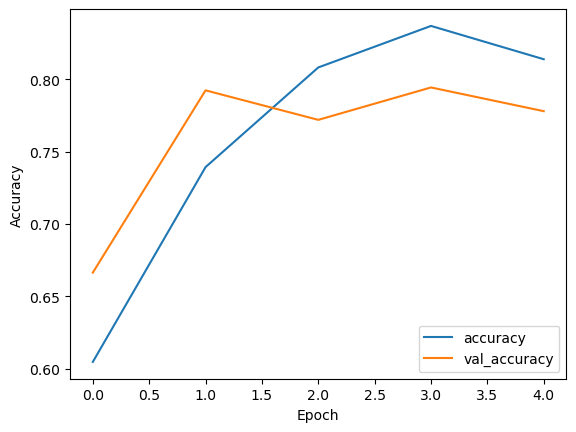

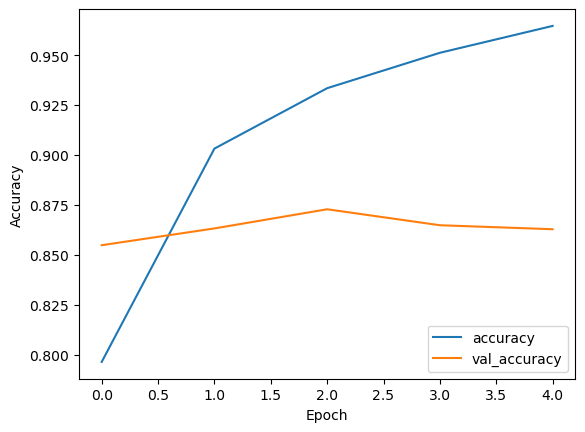

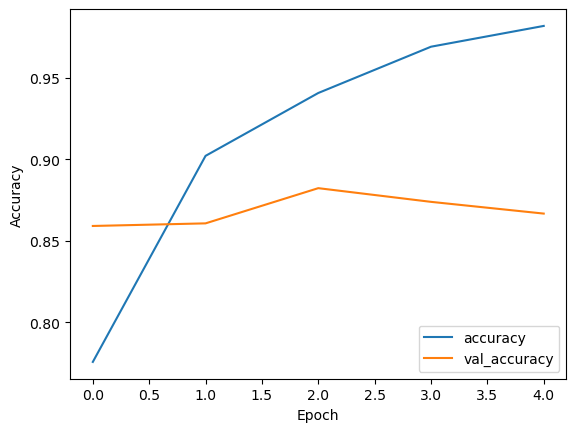

In [9]:
# Main function to run the entire pipeline
def main():
    # Hyperparameters
    num_words = 10000  # Number of words to keep from the dataset
    maxlen = 200  # Maximum length of sequences
    embedding_dim = 128
    batch_size = 64
    epochs = 5
    
    # Step 1: Load the data
    (X_train, y_train), (X_test, y_test) = load_data(num_words, maxlen)
    
    # Step 3: Split the data into training, validation, and test sets
    validation_split = 0.1
    validation_samples = int(len(X_train) * validation_split)
    X_val = X_train[:validation_samples]
    y_val = y_train[:validation_samples]
    X_train = X_train[validation_samples:]
    y_train = y_train[validation_samples:]
    
    # Step 4: Build the models
    rnn_model = build_rnn_model(num_words, embedding_dim, maxlen)
    lstm_model = build_lstm_model(num_words, embedding_dim, maxlen)
    gru_model = build_gru_model(num_words, embedding_dim, maxlen)
    
    # Step 5: Train and optimize the models
    rnn_history = train_model(rnn_model, X_train, y_train, X_val, y_val, batch_size, epochs)
    lstm_history = train_model(lstm_model, X_train, y_train, X_val, y_val, batch_size, epochs)
    gru_history = train_model(gru_model, X_train, y_train, X_val, y_val, batch_size, epochs)
    
    # Step 6: Evaluate and compare the models
    rnn_loss, rnn_accuracy = evaluate_model(rnn_model, X_test, y_test)
    lstm_loss, lstm_accuracy = evaluate_model(lstm_model, X_test, y_test)
    gru_loss, gru_accuracy = evaluate_model(gru_model, X_test, y_test)
    
    print("RNN Test Accuracy:", rnn_accuracy)
    print("LSTM Test Accuracy:", lstm_accuracy)
    print("GRU Test Accuracy:", gru_accuracy)
    
    # Step 7: Visualize and analyze results
    plot_history(rnn_history)
    plot_history(lstm_history)
    plot_history(gru_history)


if __name__ == "__main__":
    main()



# Step 7: Conclusion
Finally, we summarize the results and discuss the performance of each model.

In this final step, we summarize the results of the three models and discuss their performance. The key points to consider are:

1. **RNN Model**:
   - The simple RNN model serves as a baseline. It is expected to perform worse than LSTM and GRU due to its inability to capture long-term dependencies in text.

2. **LSTM Model**:
   - The LSTM model is expected to perform better than the RNN because it can capture long-term dependencies. It should have higher accuracy, precision, recall, and F1 score.

3. **GRU Model**:
   - The GRU model is expected to perform similarly to the LSTM but with less computational cost. It should also have high accuracy, precision, recall, and F1 score.

Finally, we compare the performance of the three models and discuss which one is the best choice for sentiment analysis on the IMDb dataset. We also reflect on the challenges faced during the project and the lessons learned.